# BlackLegend — Entregable I: análisis exploratorio de datos
**Modelos y Simulación de Sistemas II — Universidad de Antioquia**
Bryan David Molina · David Julian Penagos · Xiomara Giraldo Pérez

**Problema:** predecir si un solicitante pagará su préstamo en su totalidad (`loan_paid_back`) a partir de su información demográfica, financiera y crediticia y de las condiciones del préstamo. El modelo estima el riesgo de repago; no recomienda productos.

**Paradigma:** aprendizaje supervisado, clasificación binaria.

Este notebook reproduce las cifras, la Tabla I y las Figuras 1 a 4 del reporte del Entregable I. Las figuras del reporte se guardan en `figs/` con el mismo número que tienen en el documento; las figuras complementarias se guardan como `figs/extra_*.png`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

os.makedirs('figs', exist_ok=True)
PAGO, INCUMPLE, GRIS = '#2a78d6', '#eb6834', '#52514e'   # azul = pagó (1), naranja = incumplió (0)

# Estilo de las figuras del reporte (ancho de una columna del formato IEEE)
ESTILO_REPORTE = {'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'font.size': 7.5,
                  'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25, 'axes.titlesize': 8}
ANCHO = 3.3   # pulgadas
coma = lambda v, d=1: f'{v:.{d}f}'.replace('.', ',')          # formato decimal con coma
miles = lambda v: f'{int(v):,}'.replace(',', '.')            # separador de miles con punto

## 1. Carga y vista general

In [2]:
df = pd.read_csv('loan_dataset_20000.csv')
print('Dimensiones:', df.shape)
df.head()

Dimensiones: (20000, 22)


,age,gender,marital_status,education_level,annual_income,monthly_income,employment_status,debt_to_income_ratio,credit_score,loan_amount,...,loan_term,installment,grade_subgrade,num_of_open_accounts,total_credit_limit,current_balance,delinquency_history,public_records,num_of_delinquencies,loan_paid_back
0,59,Male,Married,Master's,24240.19,2020.02,Employed,0.074,743,17173.72,...,36,581.88,B5,7,40833.47,24302.07,1,0,1,1
1,72,Female,Married,Bachelor's,20172.98,1681.08,Employed,0.219,531,22663.89,...,60,573.17,F1,5,27968.01,10803.01,1,0,3,1
2,49,Female,Single,High School,26181.80,2181.82,Employed,0.234,779,3631.36,...,60,76.32,B4,2,15502.25,4505.44,0,0,0,1
3,35,Female,Single,High School,11873.84,989.49,Employed,0.264,809,14939.23,...,36,468.07,A5,7,18157.79,5525.63,4,0,5,1
4,63,Other,Single,Other,25326.44,2110.54,Employed,0.260,663,16551.71,...,60,395.50,D5,1,17467.56,3593.91,2,0,2,1


In [3]:
numericas_todas = df.drop(columns='loan_paid_back').select_dtypes('number').columns.tolist()
categoricas = df.select_dtypes(exclude='number').columns.tolist()
print(f'{len(numericas_todas)} predictoras numéricas y {len(categoricas)} categóricas')
pd.DataFrame({'tipo': df.dtypes.astype(str), 'valores_unicos': df.nunique(), 'nulos': df.isna().sum()})

15 predictoras numéricas y 6 categóricas


,tipo,valores_unicos,nulos
age,int64,55,0
gender,str,3,0
marital_status,str,4,0
education_level,str,5,0
annual_income,float64,19947,0
monthly_income,float64,19636,0
employment_status,str,5,0
debt_to_income_ratio,float64,555,0
credit_score,int64,399,0
loan_amount,float64,18819,0


## 2. Calidad de los datos: faltantes, duplicados y redundancias

In [4]:
print('Valores faltantes:', df.isna().sum().sum())
print('Filas duplicadas:', df.duplicated().sum())

# ¿monthly_income es simplemente annual_income / 12?
dif = (df['annual_income'] / 12 - df['monthly_income']).abs()
print(f'Diferencia máxima |annual_income/12 - monthly_income| = {dif.max():.3f}')
print(f"Correlación annual_income vs monthly_income = {df['annual_income'].corr(df['monthly_income']):.4f}")

Valores faltantes: 0
Filas duplicadas: 0
Diferencia máxima |annual_income/12 - monthly_income| = 0.005
Correlación annual_income vs monthly_income = 1.0000


No hay faltantes ni duplicados, así que no se necesita imputación. `monthly_income` es `annual_income / 12` (la diferencia solo se debe al redondeo), por lo que es redundante y se eliminará.

## 3. Variable objetivo: balance de clases (Fig. 1)

,n,proporción
loan_paid_back,,
0 = incumplió,4002,0.2001
1 = pagó,15998,0.7999


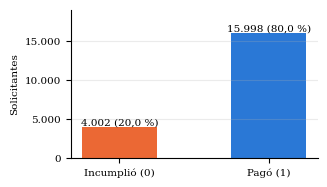

In [5]:
conteo = df['loan_paid_back'].value_counts().sort_index()
prop = conteo / conteo.sum()
display(pd.DataFrame({'n': conteo, 'proporción': prop.round(4)}).rename(index={0: '0 = incumplió', 1: '1 = pagó'}))

with plt.rc_context(ESTILO_REPORTE):
    fig, ax = plt.subplots(figsize=(ANCHO, 1.9))
    barras = ax.bar(['Incumplió (0)', 'Pagó (1)'], conteo.values, color=[INCUMPLE, PAGO], width=0.5)
    for b, p in zip(barras, prop):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 250, f'{miles(b.get_height())} ({coma(p * 100)} %)', ha='center')
    ax.set_ylim(0, 19000); ax.set_ylabel('Solicitantes'); ax.grid(axis='x', visible=False)
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: miles(v)))
    fig.tight_layout(); fig.savefig('figs/fig1_balance.png', dpi=300, bbox_inches='tight'); plt.show()

Hay un desbalance de 80/20: un clasificador que siempre prediga "pagó" tendría 80 % de *accuracy* sin aprender nada. Por eso habrá que usar métricas que tengan en cuenta la clase minoritaria; su selección se hará en el Entregable II.

## 4. Variables numéricas (Tabla I)

In [6]:
num_cols = ['age', 'annual_income', 'debt_to_income_ratio', 'credit_score', 'loan_amount',
            'interest_rate', 'loan_term', 'installment', 'num_of_open_accounts', 'total_credit_limit',
            'current_balance', 'delinquency_history', 'public_records', 'num_of_delinquencies']
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,20000.0,48.03,15.83,21.00,35.00,48.00,62.00,75.00
annual_income,20000.0,43549.64,28668.58,6000.00,24260.75,36585.26,54677.92,400000.00
debt_to_income_ratio,20000.0,0.18,0.11,0.01,0.10,0.16,0.24,0.67
credit_score,20000.0,679.26,69.64,373.00,632.00,680.00,727.00,850.00
loan_amount,20000.0,15129.30,8605.41,500.00,8852.70,14946.17,20998.87,49039.69
interest_rate,20000.0,12.40,2.44,3.14,10.74,12.40,14.00,22.51
loan_term,20000.0,43.22,11.01,36.00,36.00,36.00,60.00,60.00
installment,20000.0,455.63,274.62,9.43,253.91,435.60,633.60,1685.40
num_of_open_accounts,20000.0,5.01,2.24,0.00,3.00,5.00,6.00,15.00
total_credit_limit,20000.0,48649.82,32423.38,6157.80,27180.49,40241.62,60361.26,454394.19


In [7]:
print('Valores de loan_term:', sorted(df['loan_term'].unique()))
print('Asimetría de las variables monetarias:')
df[['annual_income', 'total_credit_limit', 'current_balance']].skew().round(2)

Valores de loan_term: [np.int64(36), np.int64(60)]
Asimetría de las variables monetarias:


annual_income         2.33
total_credit_limit    2.49
current_balance       2.79
dtype: float64

In [8]:
# Tabla I del reporte
tabla_vars = ['age', 'annual_income', 'debt_to_income_ratio', 'credit_score', 'loan_amount', 'interest_rate', 'num_of_delinquencies']
tabla_I = df[tabla_vars].agg(['min', 'median', 'max', 'mean']).T
tabla_I.columns = ['Mín.', 'Mediana', 'Máx.', 'Media']
tabla_I.round(3)

,Mín.,Mediana,Máx.,Media
age,21.00,48.00,75.000,48.027
annual_income,6000.00,36585.26,400000.000,43549.638
debt_to_income_ratio,0.01,0.16,0.667,0.177
credit_score,373.00,680.00,850.000,679.257
loan_amount,500.00,14946.17,49039.690,15129.301
interest_rate,3.14,12.40,22.510,12.401
num_of_delinquencies,0.00,2.00,11.000,2.489


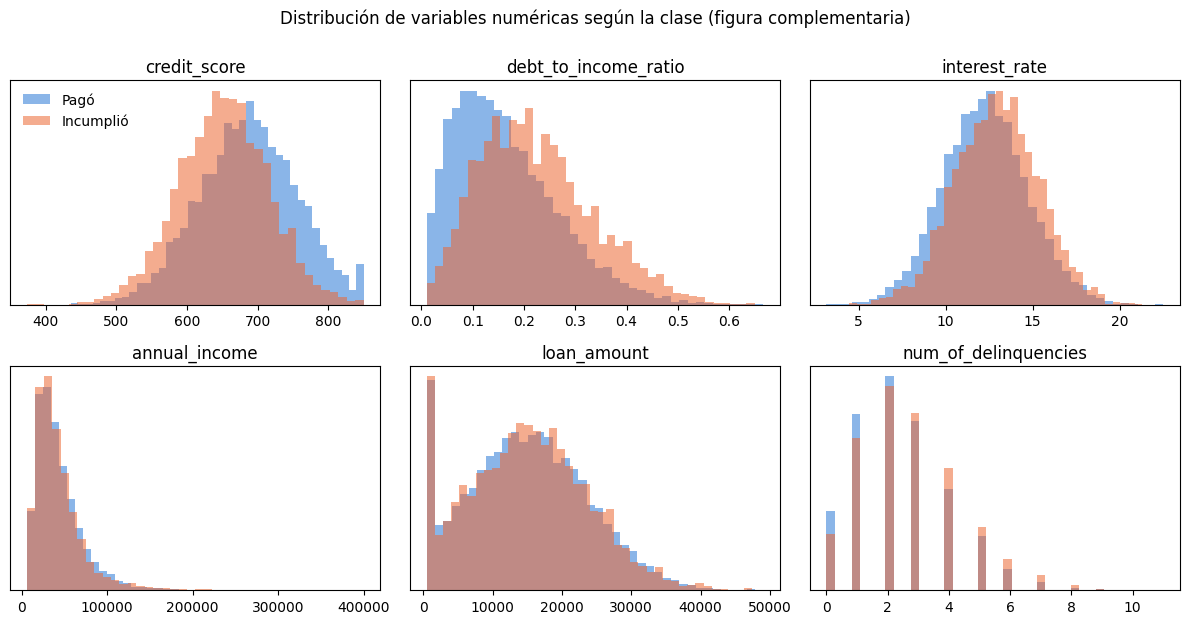

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for ax, c in zip(axes.ravel(), ['credit_score', 'debt_to_income_ratio', 'interest_rate', 'annual_income', 'loan_amount', 'num_of_delinquencies']):
    for clase, nombre, color in [(1, 'Pagó', PAGO), (0, 'Incumplió', INCUMPLE)]:
        ax.hist(df.loc[df.loan_paid_back == clase, c], bins=40, density=True, alpha=0.55, color=color, label=nombre)
    ax.set_title(c); ax.set_yticks([])
axes[0, 0].legend(frameon=False)
fig.suptitle('Distribución de variables numéricas según la clase (figura complementaria)', y=1.0)
plt.tight_layout(); plt.savefig('figs/extra_histogramas.png', dpi=200, bbox_inches='tight'); plt.show()

## 5. Correlación con la variable objetivo (Fig. 2)

debt_to_income_ratio   -0.224
interest_rate          -0.111
delinquency_history    -0.085
num_of_delinquencies   -0.071
installment            -0.010
current_balance        -0.005
total_credit_limit     -0.003
loan_term              -0.003
loan_amount            -0.002
num_of_open_accounts    0.003
annual_income           0.003
public_records          0.003
age                     0.008
credit_score            0.200
Name: loan_paid_back, dtype: float64

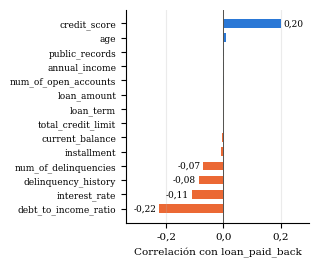

In [10]:
corr_t = df[num_cols + ['loan_paid_back']].corr()['loan_paid_back'].drop('loan_paid_back').sort_values()
display(corr_t.round(3))

with plt.rc_context(ESTILO_REPORTE):
    fig, ax = plt.subplots(figsize=(ANCHO, 2.7))
    ax.barh(corr_t.index, corr_t.values, color=[INCUMPLE if v < 0 else PAGO for v in corr_t.values], height=0.6)
    ax.axvline(0, color=GRIS, lw=0.7)
    for i, v in enumerate(corr_t.values):
        if abs(v) > 0.05:
            ax.text(v + (0.01 if v > 0 else -0.01), i, coma(v, 2), va='center', ha='left' if v > 0 else 'right', fontsize=6.5)
    ax.set_xlim(-0.34, 0.3); ax.set_xlabel('Correlación con loan_paid_back')
    ax.grid(axis='y', visible=False); ax.tick_params(axis='y', labelsize=6.5)
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: coma(v)))
    fig.tight_layout(); fig.savefig('figs/fig2_correlacion.png', dpi=300, bbox_inches='tight'); plt.show()

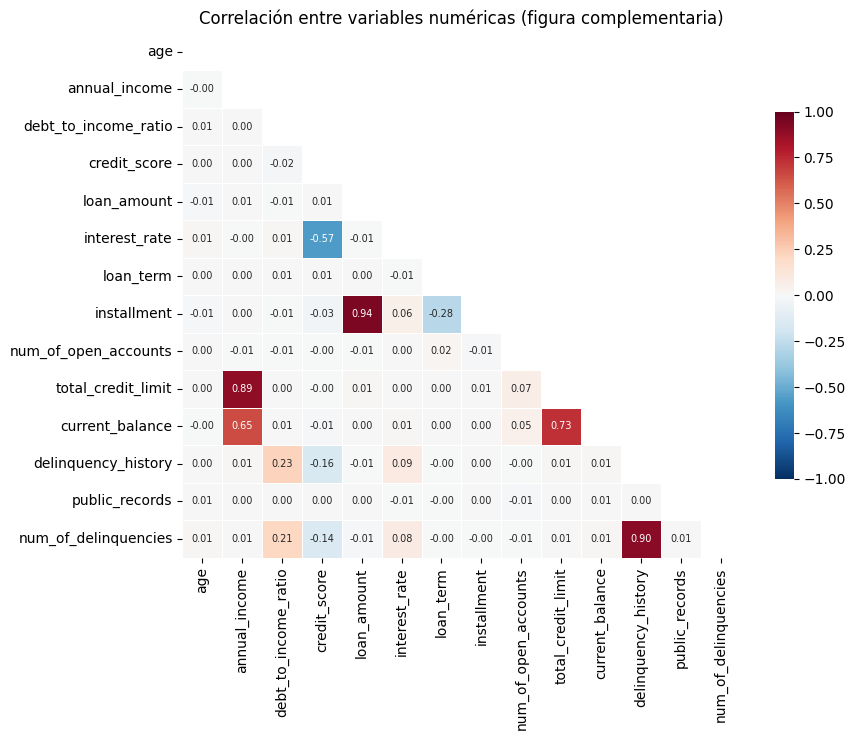

In [11]:
fig, ax = plt.subplots(figsize=(9, 7.5))
m = df[num_cols].corr()
sns.heatmap(m, mask=np.triu(np.ones_like(m, dtype=bool)), cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', annot_kws={'size': 7}, linewidths=0.5, cbar_kws={'shrink': 0.7}, ax=ax)
ax.set_title('Correlación entre variables numéricas (figura complementaria)')
plt.tight_layout(); plt.savefig('figs/extra_heatmap.png', dpi=200, bbox_inches='tight'); plt.show()

## 6. Variables categóricas: tasa de pago por categoría (Fig. 3)

In [12]:
cat_cols = ['gender', 'marital_status', 'education_level', 'employment_status', 'loan_purpose']
for c in cat_cols:
    t = df.groupby(c)['loan_paid_back'].agg(n='size', tasa_pago='mean').sort_values('tasa_pago')
    print(f'--- {c} ({df[c].nunique()} categorías)'); print(t.round(3), end='\n\n')
print('Registros con education_level = "Other":', (df['education_level'] == 'Other').sum())

--- gender (3 categorías)
            n  tasa_pago
gender                  
Other     430      0.793
Male     9536      0.798
Female  10034      0.802

--- marital_status (4 categorías)
                   n  tasa_pago
marital_status                 
Widowed          567      0.785
Single          9031      0.800
Married         8974      0.800
Divorced        1428      0.805

--- education_level (5 categorías)
                    n  tasa_pago
education_level                 
Bachelor's       8045      0.791
Master's         3724      0.798
Other            1508      0.804
High School      5919      0.808
PhD               804      0.828

--- employment_status (5 categorías)
                       n  tasa_pago
employment_status                  
Unemployed          2113      0.182
Student              781      0.407
Self-employed       2923      0.886
Employed           13007      0.887
Retired             1176      0.995

--- loan_purpose (8 categorías)
                       n  tasa_p

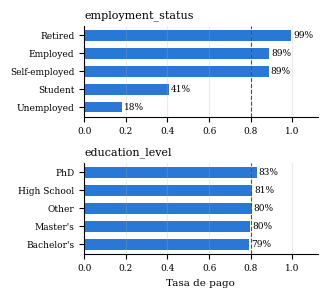

In [13]:
tasa_global = df['loan_paid_back'].mean()
with plt.rc_context(ESTILO_REPORTE):
    fig, axes = plt.subplots(2, 1, figsize=(ANCHO, 3.0))
    for ax, c in zip(axes, ['employment_status', 'education_level']):
        t = df.groupby(c)['loan_paid_back'].mean().sort_values()
        ax.barh(t.index, t.values, color=PAGO, height=0.6); ax.axvline(tasa_global, color=GRIS, ls='--', lw=0.8)
        for i, v in enumerate(t.values): ax.text(v + 0.01, i, f'{v:.0%}', va='center', fontsize=6.5)
        ax.set_xlim(0, 1.12); ax.set_title(c, loc='left'); ax.grid(axis='y', visible=False); ax.tick_params(labelsize=6.5)
    axes[1].set_xlabel('Tasa de pago')
    fig.tight_layout(); fig.savefig('figs/fig3_categoricas.png', dpi=300, bbox_inches='tight'); plt.show()

## 7. `grade_subgrade` y posible fuga de información (Fig. 4)

Las categorías son exactamente A1..F5: True


grade_subgrade,A1,A2,A3,A4,A5,B1,B2,B3,B4,B5,...,E1,E2,E3,E4,E5,F1,F2,F3,F4,F5
tasa_pago,0.96,0.962,0.946,0.925,0.937,0.889,0.916,0.912,0.918,0.904,...,0.7,0.701,0.697,0.69,0.725,0.654,0.679,0.659,0.677,0.706


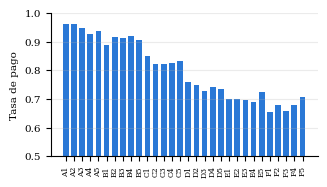

Correlación de Spearman entre grade_subgrade (ordinal) e interest_rate: 0.51


In [14]:
orden_grade = [f'{g}{i}' for g in 'ABCDEF' for i in range(1, 6)]
print('Las categorías son exactamente A1..F5:', sorted(df['grade_subgrade'].unique()) == orden_grade)
tasa_grade = df.groupby('grade_subgrade')['loan_paid_back'].mean().reindex(orden_grade)
display(tasa_grade.round(3).to_frame('tasa_pago').T)

with plt.rc_context(ESTILO_REPORTE):
    fig, ax = plt.subplots(figsize=(ANCHO, 1.9))
    ax.bar(orden_grade, tasa_grade.values, color=PAGO, width=0.7); ax.set_ylim(0.5, 1)
    ax.set_ylabel('Tasa de pago'); ax.tick_params(axis='x', rotation=90, labelsize=5.5); ax.grid(axis='x', visible=False)
    fig.tight_layout(); fig.savefig('figs/fig4_grade.png', dpi=300, bbox_inches='tight'); plt.show()

rho = df['grade_subgrade'].map({k: i for i, k in enumerate(orden_grade)}).corr(df['interest_rate'], method='spearman')
print(f'Correlación de Spearman entre grade_subgrade (ordinal) e interest_rate: {rho:.2f}')

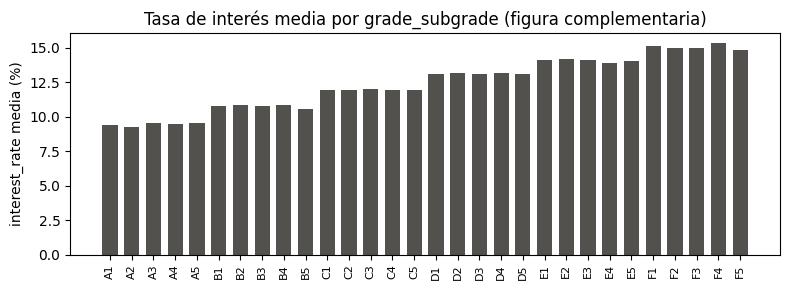

In [15]:
tasa_interes = df.groupby('grade_subgrade')['interest_rate'].mean().reindex(orden_grade)
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(orden_grade, tasa_interes.values, color=GRIS, width=0.7)
ax.set_ylabel('interest_rate media (%)'); ax.set_title('Tasa de interés media por grade_subgrade (figura complementaria)')
ax.tick_params(axis='x', rotation=90, labelsize=8)
plt.tight_layout(); plt.savefig('figs/extra_interes_por_grade.png', dpi=200, bbox_inches='tight'); plt.show()

La tasa de pago baja de forma casi monótona de A1 (96 %) a la categoría F (65–71 %), lo que justifica el *Ordinal Encoding*. Pero `grade_subgrade`, `interest_rate` e `installment` son condiciones que asigna la entidad después de evaluar el riesgo, así que usarlas como entrada puede generar fuga de información. Por eso se plantean dos escenarios:
- **Escenario A (perfil del solicitante):** sin `grade_subgrade`, `interest_rate` ni `installment`.
- **Escenario B (todas las variables):** como referencia del desempeño máximo.

## 8. Codificación propuesta

In [16]:
nominales = ['gender', 'marital_status', 'education_level', 'employment_status', 'loan_purpose']
fuga = ['grade_subgrade', 'interest_rate', 'installment']
descartar = ['monthly_income', 'loan_paid_back']
numericas_A = [c for c in df.columns if c not in nominales + fuga + descartar]

# Solo se cuenta cuántas columnas genera la codificación del escenario A.
# El ajuste real del escalador se hará solo con los datos de entrenamiento en el Entregable II.
codificador_A = ColumnTransformer([('num', StandardScaler(), numericas_A),
                                   ('cat', OneHotEncoder(handle_unknown='ignore'), nominales)])
n_vars = codificador_A.fit(df[numericas_A + nominales]).transform(df[numericas_A + nominales].head(1)).shape[1]
print(f'{len(numericas_A)} numéricas + {sum(df[c].nunique() for c in nominales)} columnas One-Hot = {n_vars} variables de entrada (escenario A)')

12 numéricas + 25 columnas One-Hot = 37 variables de entrada (escenario A)


## 9. Resumen de hallazgos
1. 20.000 registros y 22 columnas (21 predictoras y la variable objetivo), sin faltantes ni duplicados.
2. Desbalance de 80/20: *accuracy* no es suficiente; las métricas se definirán en el Entregable II.
3. `monthly_income` es redundante (`annual_income`/12) y se eliminará.
4. `loan_term` solo toma 36 o 60 meses; `grade_subgrade` tiene 30 niveles (A1–F5) con una relación casi monótona con el pago.
5. Las variables que más se relacionan con el pago son `debt_to_income_ratio`, `credit_score`, `employment_status` y `grade_subgrade`/`interest_rate`.
6. `grade_subgrade`, `interest_rate` e `installment` implican riesgo de fuga de información, por eso se plantean dos escenarios.